# VQ-VAE — Interfaz de Evaluación
Carga el modelo entrenado y evalúa imágenes arbitrarias: originales, modificadas y outliers.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from torchvision import transforms
from pathlib import Path
import random

# Detectar dispositivo (MPS en M4, CPU como fallback)
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
    print('Usando MPS (Apple Silicon)')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    print('Usando CUDA')
else:
    DEVICE = torch.device('cpu')
    print('Usando CPU')

CHECKPOINT = 'results/vqvae/checkpoints/vqvae-epoch=06-train/loss=0.0003.ckpt'
IMAGE_DIR  = Path('data/sample_imgs')
IMAGE_SIZE = 256

Usando MPS (Apple Silicon)


In [3]:
import sys
sys.path.insert(0, 'src')
from models.vqvae.model import VQVAE

# Cargar modelo desde checkpoint
model = VQVAE.load_from_checkpoint(CHECKPOINT, map_location=DEVICE)
model = model.to(DEVICE)
model.eval()
print('Modelo cargado correctamente')
print(f'  num_embeddings : {model.hparams.num_embeddings}')
print(f'  embedding_dim  : {model.hparams.embedding_dim}')
print(f'  hidden_channels: {model.hparams.hidden_channels}')

Modelo cargado correctamente
  num_embeddings : 512
  embedding_dim  : 256
  hidden_channels: [64, 128, 256]


In [4]:
# Transformaciones: igual que en entrenamiento
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

def load_image(path):
    img = Image.open(path).convert('RGB')
    return transform(img).unsqueeze(0)  # [1, 3, H, W]

def tensor_to_display(t):
    """Convierte tensor normalizado [-1,1] a imagen numpy [0,1]"""
    t = t.squeeze(0).cpu().clamp(-1, 1)
    t = (t + 1) / 2
    return t.permute(1, 2, 0).numpy()

def reconstruct(img_tensor):
    with torch.no_grad():
        img_tensor = img_tensor.to(DEVICE)
        x_hat, vq_loss, indices, perplexity, _, _ = model(img_tensor)
    recon_loss = torch.nn.functional.mse_loss(x_hat, img_tensor).item()
    return x_hat, indices, recon_loss, perplexity.item()

print('Funciones de utilidad listas')

Funciones de utilidad listas


## 1. Reconstrucción de imágenes originales

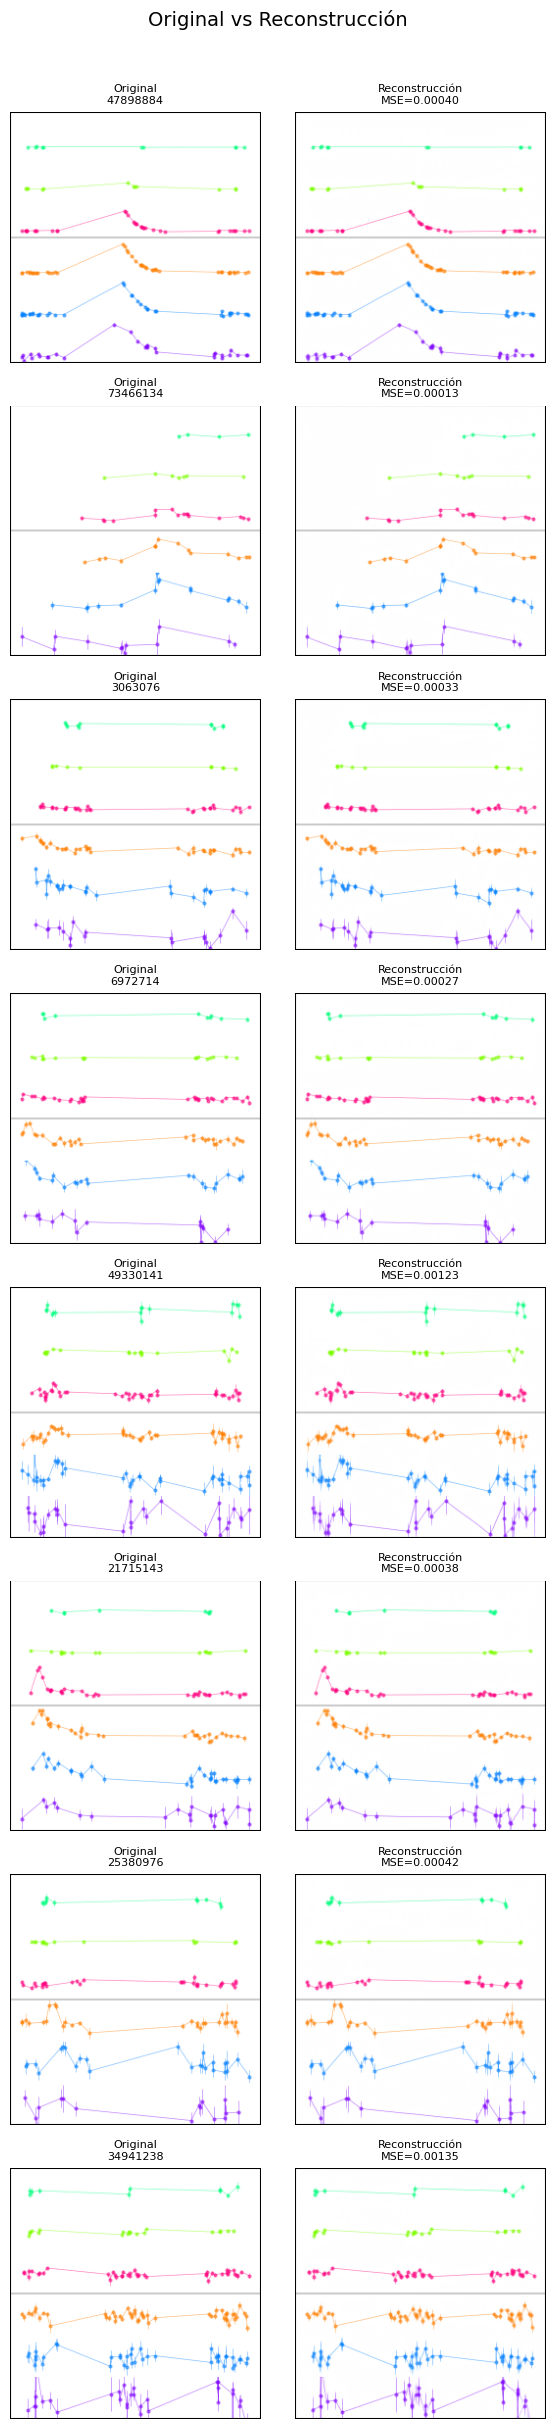

Guardado en results/reconstructions_original.png


In [11]:
# Cargar N imágenes aleatorias de la muestra
N = 8
image_paths = list(IMAGE_DIR.glob('*.png'))
selected = random.sample(image_paths, min(N, len(image_paths)))

fig, axes = plt.subplots(N, 2, figsize=(6, N * 3))
fig.suptitle('Original vs Reconstrucción', fontsize=14, y=1.01)

for i, path in enumerate(selected):
    img_tensor = load_image(path)
    x_hat, indices, recon_loss, perplexity = reconstruct(img_tensor)

    orig  = tensor_to_display(img_tensor)
    recon = tensor_to_display(x_hat)

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f'Original\n{path.stem}', fontsize=8)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(recon)
    axes[i, 1].set_title(f'Reconstrucción\nMSE={recon_loss:.5f}', fontsize=8)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig('results/reconstructions_original.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado en results/reconstructions_original.png')

## 2. Evaluar imagen arbitraria (cualquier ruta)

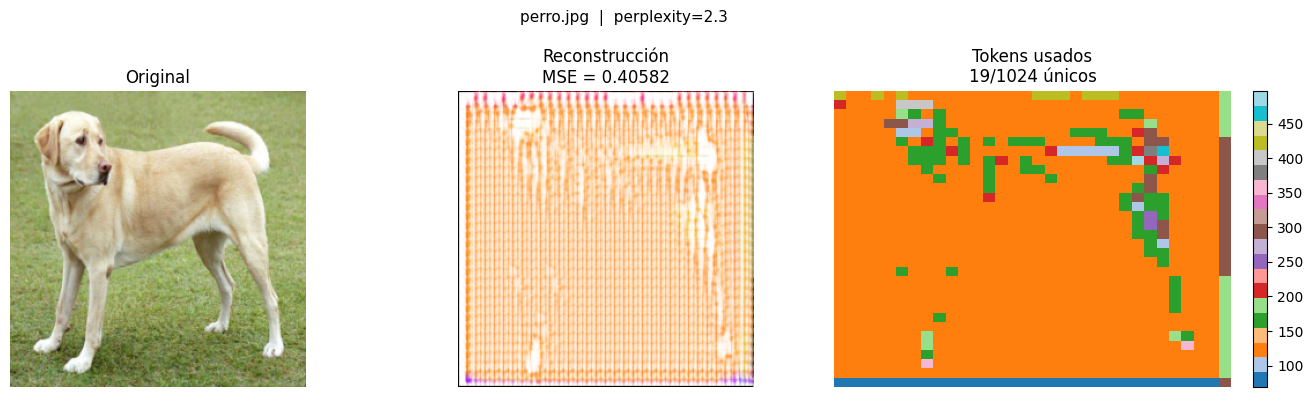

MSE recon loss : 0.405823
Tokens únicos  : 19 / 1024
Perplexity     : 2.34


0.4058226943016052

In [10]:
def evaluate_single(image_path):
    """Evalúa una imagen arbitraria y muestra original + reconstrucción + tokens usados"""
    img_tensor = load_image(image_path)
    x_hat, indices, recon_loss, perplexity = reconstruct(img_tensor)

    orig  = tensor_to_display(img_tensor)
    recon = tensor_to_display(x_hat)

    unique_tokens = indices.unique().numel()
    total_tokens  = indices.numel()

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].imshow(orig)
    axes[0].set_title('Original', fontsize=12)
    axes[0].axis('off')

    axes[1].imshow(recon)
    axes[1].set_title(f'Reconstrucción\nMSE = {recon_loss:.5f}', fontsize=12)
    axes[1].axis('off')

    # Mapa de tokens
    token_map = indices.squeeze(0).cpu().numpy()  # [H', W']
    im = axes[2].imshow(token_map, cmap='tab20', aspect='auto')
    axes[2].set_title(f'Tokens usados\n{unique_tokens}/{total_tokens} únicos', fontsize=12)
    axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    plt.suptitle(f'{Path(image_path).name}  |  perplexity={perplexity:.1f}', fontsize=11)
    plt.tight_layout()
    plt.show()

    print(f'MSE recon loss : {recon_loss:.6f}')
    print(f'Tokens únicos  : {unique_tokens} / {total_tokens}')
    print(f'Perplexity     : {perplexity:.2f}')
    return recon_loss

test_path = 'data/sample_imgs/perro.jpg'
evaluate_single(test_path)

## 3. Outliers — imágenes completamente artificiales

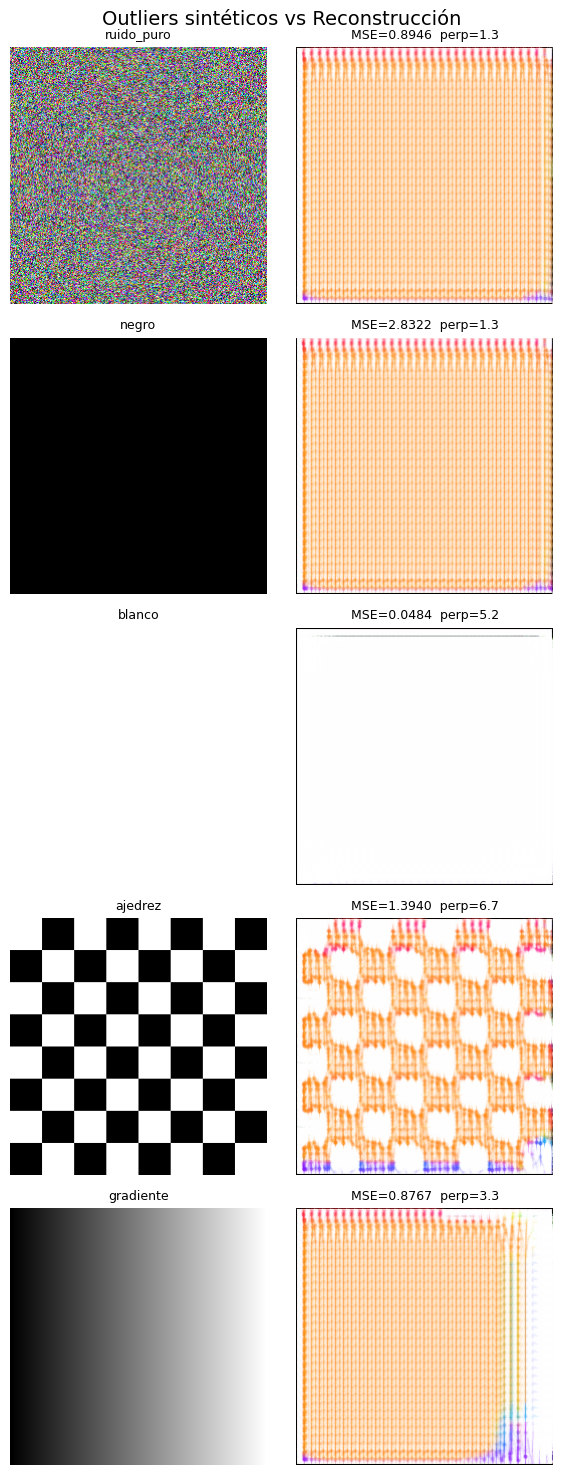


Resumen de pérdidas:
  negro          : MSE = 2.83218
  ajedrez        : MSE = 1.39398
  ruido_puro     : MSE = 0.89460
  gradiente      : MSE = 0.87668
  blanco         : MSE = 0.04842


In [7]:
def make_outlier_images():
    """Genera imágenes outlier sintéticas para ver cómo responde el modelo"""
    outliers = {}

    # Ruido puro
    noise = torch.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE) * 2 - 1
    outliers['ruido_puro'] = noise

    # Imagen completamente negra
    outliers['negro'] = torch.full((1, 3, IMAGE_SIZE, IMAGE_SIZE), -1.0)

    # Imagen completamente blanca
    outliers['blanco'] = torch.full((1, 3, IMAGE_SIZE, IMAGE_SIZE), 1.0)

    # Patrón de tablero de ajedrez
    chess = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)
    for i in range(IMAGE_SIZE):
        for j in range(IMAGE_SIZE):
            if (i // 32 + j // 32) % 2 == 0:
                chess[0, :, i, j] = 1.0
            else:
                chess[0, :, i, j] = -1.0
    outliers['ajedrez'] = chess

    # Gradiente horizontal
    grad = torch.linspace(-1, 1, IMAGE_SIZE).view(1, 1, IMAGE_SIZE).expand(1, IMAGE_SIZE, IMAGE_SIZE)
    outliers['gradiente'] = grad.unsqueeze(0).expand(1, 3, IMAGE_SIZE, IMAGE_SIZE).clone()

    return outliers

outliers = make_outlier_images()
losses = {}

fig, axes = plt.subplots(len(outliers), 2, figsize=(6, len(outliers) * 3))
fig.suptitle('Outliers sintéticos vs Reconstrucción', fontsize=14)

for i, (name, img_tensor) in enumerate(outliers.items()):
    x_hat, indices, recon_loss, perplexity = reconstruct(img_tensor)
    losses[name] = recon_loss

    orig  = tensor_to_display(img_tensor)
    recon = tensor_to_display(x_hat)

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f'{name}', fontsize=9)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(recon)
    axes[i, 1].set_title(f'MSE={recon_loss:.4f}  perp={perplexity:.1f}', fontsize=9)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig('results/reconstructions_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nResumen de pérdidas:')
for name, loss in sorted(losses.items(), key=lambda x: -x[1]):
    print(f'  {name:15s}: MSE = {loss:.5f}')

## 4. LCs modificadas — perturbaciones sobre imágenes reales

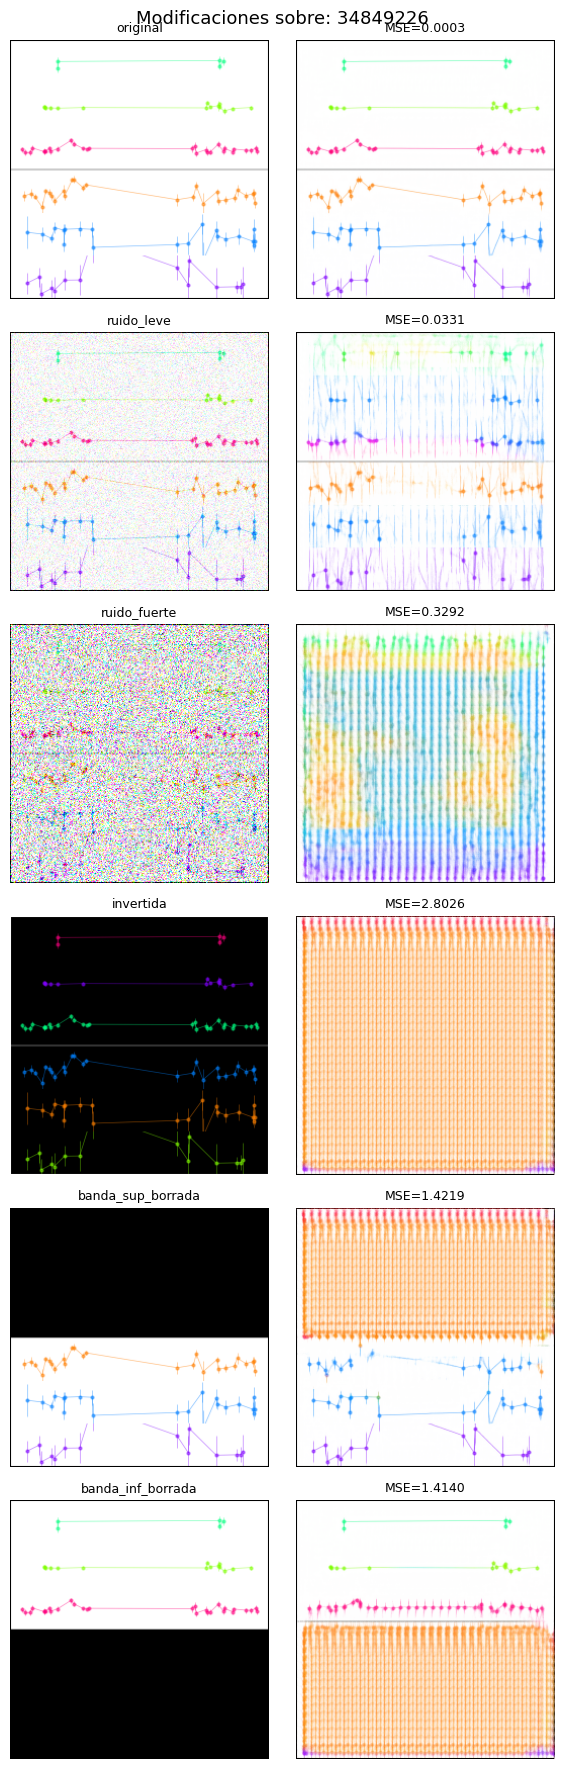


Pérdidas por modificación (mayor = más outlier):
  invertida             : MSE = 2.80255
  banda_sup_borrada     : MSE = 1.42193
  banda_inf_borrada     : MSE = 1.41399
  ruido_fuerte          : MSE = 0.32920
  ruido_leve            : MSE = 0.03310
  original              : MSE = 0.00030


In [8]:
def make_modifications(img_tensor):
    """Genera versiones modificadas de una imagen real"""
    mods = {'original': img_tensor.clone()}

    # Ruido gaussiano leve
    noisy = img_tensor.clone() + torch.randn_like(img_tensor) * 0.2
    mods['ruido_leve'] = noisy.clamp(-1, 1)

    # Ruido gaussiano fuerte
    noisy_strong = img_tensor.clone() + torch.randn_like(img_tensor) * 0.8
    mods['ruido_fuerte'] = noisy_strong.clamp(-1, 1)

    # Invertir la imagen (negar todos los pixeles)
    mods['invertida'] = -img_tensor.clone()

    # Borrar banda superior (simula bandas faltantes)
    masked = img_tensor.clone()
    masked[0, :, :IMAGE_SIZE//2, :] = -1.0
    mods['banda_sup_borrada'] = masked

    # Borrar banda inferior
    masked2 = img_tensor.clone()
    masked2[0, :, IMAGE_SIZE//2:, :] = -1.0
    mods['banda_inf_borrada'] = masked2

    return mods

# Tomar una imagen de referencia
ref_path = list(IMAGE_DIR.glob('*.png'))[3]
ref_tensor = load_image(ref_path)
mods = make_modifications(ref_tensor)

fig, axes = plt.subplots(len(mods), 2, figsize=(6, len(mods) * 3))
fig.suptitle(f'Modificaciones sobre: {ref_path.stem}', fontsize=13)
mod_losses = {}

for i, (name, img_tensor) in enumerate(mods.items()):
    x_hat, indices, recon_loss, perplexity = reconstruct(img_tensor)
    mod_losses[name] = recon_loss

    axes[i, 0].imshow(tensor_to_display(img_tensor))
    axes[i, 0].set_title(name, fontsize=9)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(tensor_to_display(x_hat))
    axes[i, 1].set_title(f'MSE={recon_loss:.4f}', fontsize=9)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig('results/reconstructions_modified.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nPérdidas por modificación (mayor = más outlier):')
for name, loss in sorted(mod_losses.items(), key=lambda x: -x[1]):
    print(f'  {name:22s}: MSE = {loss:.5f}')

## 5. Comparativa de pérdidas: originales vs outliers vs modificadas

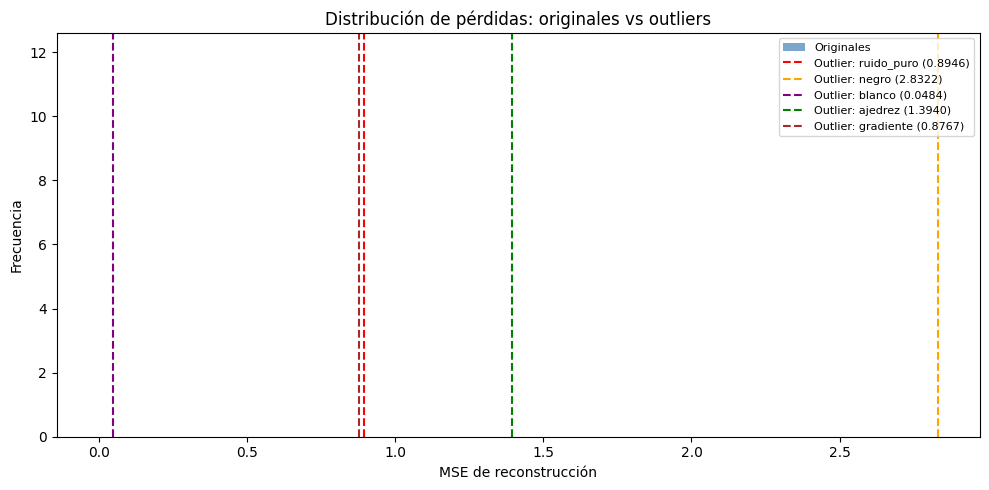

Originales — media: 0.00039, std: 0.00030


In [9]:
# Calcular pérdida de reconstrucción para todas las imágenes de la muestra
all_paths = list(IMAGE_DIR.glob('*.png'))
original_losses = []

for path in all_paths:
    img_tensor = load_image(path)
    _, _, recon_loss, _ = reconstruct(img_tensor)
    original_losses.append(recon_loss)

fig, ax = plt.subplots(figsize=(10, 5))

# Histograma de originales
ax.hist(original_losses, bins=15, alpha=0.7, label='Originales', color='steelblue')

# Líneas verticales para outliers sintéticos
colors_outlier = ['red', 'orange', 'purple', 'green', 'brown']
for (name, loss), color in zip(losses.items(), colors_outlier):
    ax.axvline(loss, color=color, linestyle='--', linewidth=1.5, label=f'Outlier: {name} ({loss:.4f})')

ax.set_xlabel('MSE de reconstrucción')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de pérdidas: originales vs outliers')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('results/loss_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Originales — media: {np.mean(original_losses):.5f}, std: {np.std(original_losses):.5f}')

=== Curvas reales ===
            MSE  perplexity  tokens_unicos
count  50.00000    50.00000       50.00000
mean    0.00039   167.10655      295.04000
std     0.00031    47.61788       45.08856
min     0.00008    68.17968      202.00000
25%     0.00018   143.35323      269.50000
50%     0.00033   173.53153      302.00000
75%     0.00044   190.91457      318.50000
max     0.00135   256.38251      375.00000

=== Perro ===
     MSE  perplexity  tokens_unicos
0.405823    2.337532             19


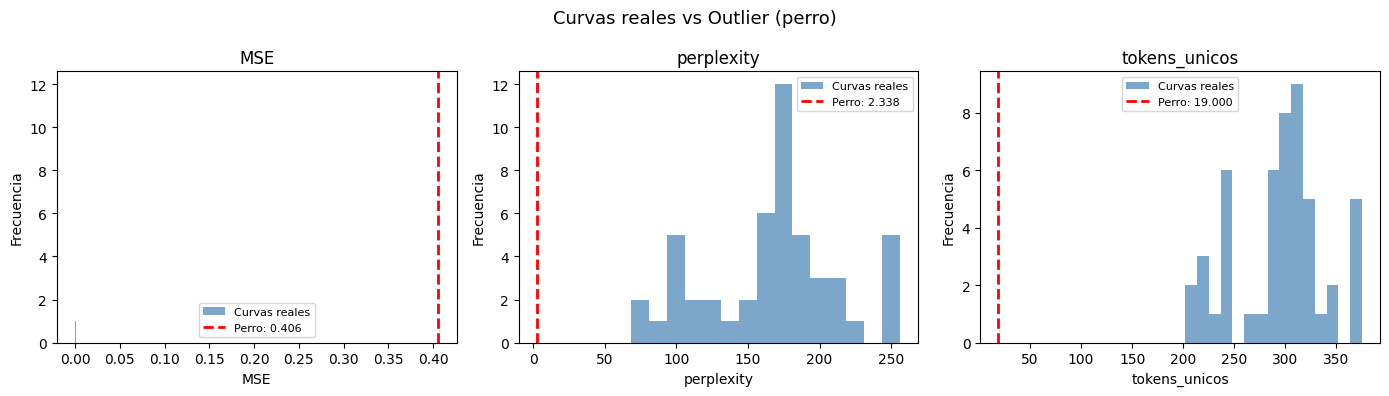

In [12]:
# Métricas comparativas: originales vs perro
import pandas as pd

def get_metrics(img_tensor):
    x_hat, indices, recon_loss, perplexity = reconstruct(img_tensor)
    unique_tokens = indices.unique().numel()
    return recon_loss, perplexity, unique_tokens

# Calcular métricas para todas las imágenes de la muestra
records = []
for path in list(IMAGE_DIR.glob('*.png')):
    img_tensor = load_image(path)
    mse, perp, unique = get_metrics(img_tensor)
    records.append({'nombre': path.stem, 'tipo': 'curva_real', 'MSE': mse, 'perplexity': perp, 'tokens_unicos': unique})

# Agregar el perro
img_tensor = load_image('data/sample_imgs/perro.jpg')
mse, perp, unique = get_metrics(img_tensor)
records.append({'nombre': 'perro', 'tipo': 'outlier', 'MSE': mse, 'perplexity': perp, 'tokens_unicos': unique})

df = pd.DataFrame(records)

# Resumen estadístico
print("=== Curvas reales ===")
print(df[df.tipo == 'curva_real'][['MSE','perplexity','tokens_unicos']].describe().round(5))
print("\n=== Perro ===")
print(df[df.tipo == 'outlier'][['MSE','perplexity','tokens_unicos']].to_string(index=False))

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Curvas reales vs Outlier (perro)', fontsize=13)

metricas = ['MSE', 'perplexity', 'tokens_unicos']
colores  = ['steelblue', 'steelblue', 'steelblue']

for ax, metrica, color in zip(axes, metricas, colores):
    vals = df[df.tipo == 'curva_real'][metrica].values
    ax.hist(vals, bins=15, color=color, alpha=0.7, label='Curvas reales')
    val_perro = df[df.tipo == 'outlier'][metrica].values[0]
    ax.axvline(val_perro, color='red', linestyle='--', linewidth=2, label=f'Perro: {val_perro:.3f}')
    ax.set_title(metrica)
    ax.set_xlabel(metrica)
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('results/metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

/var/folders/cs/xgww49716jv0576mvxdmr4wh0000gn/T/ipykernel_27484/788633946.py:88: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


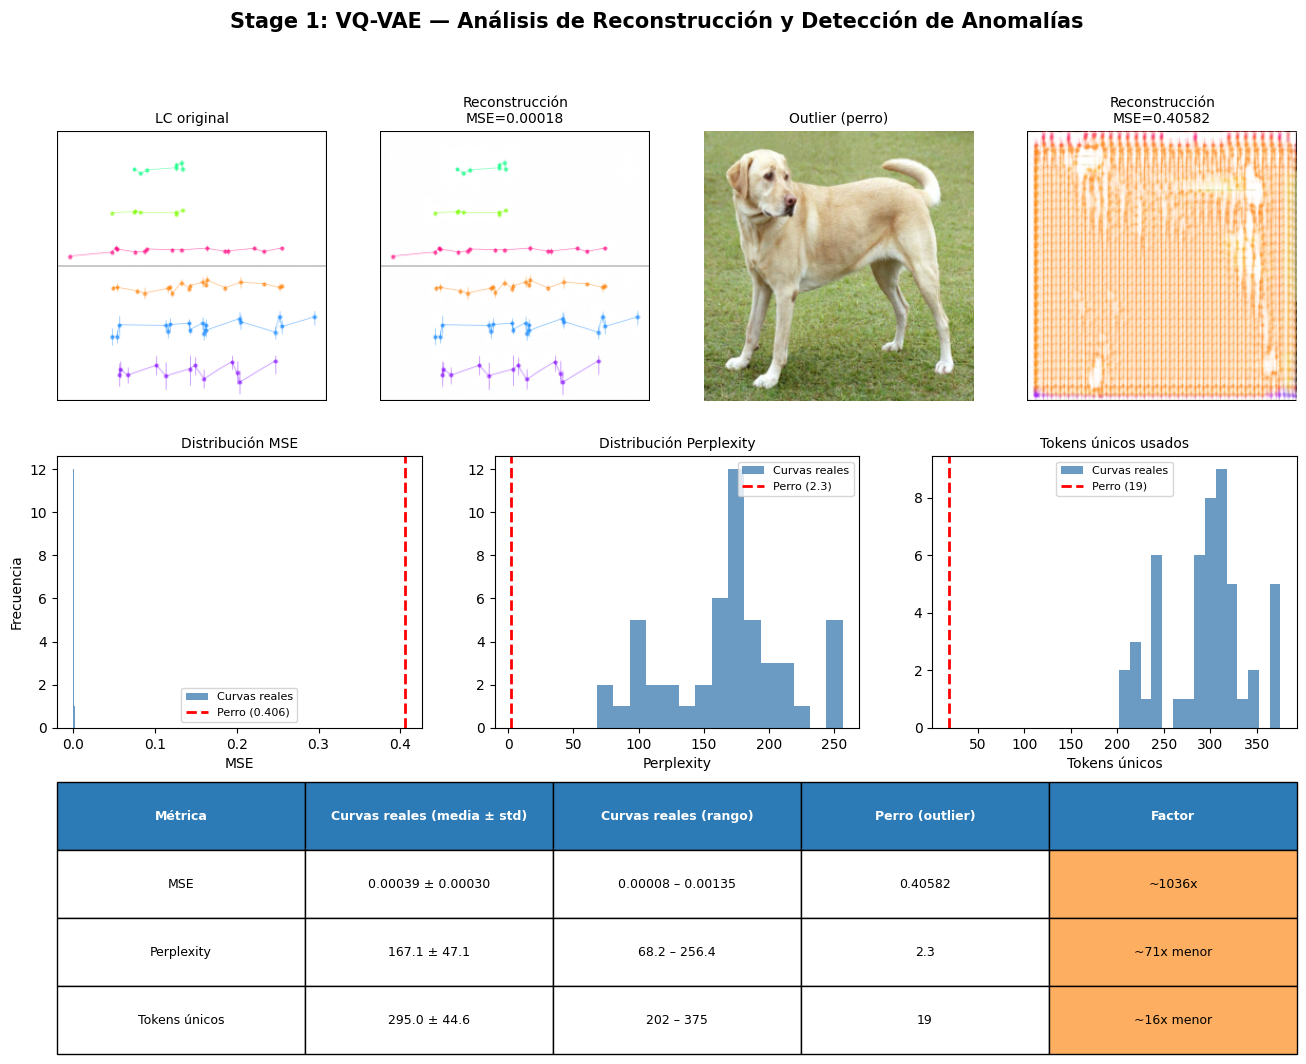

Guardado en results/stage1_summary.png


In [13]:
# ============================================================
# FIGURA RESUMEN STAGE 1 — Para tesis
# ============================================================
fig = plt.figure(figsize=(16, 12))
fig.suptitle('Stage 1: VQ-VAE — Análisis de Reconstrucción y Detección de Anomalías', 
             fontsize=15, fontweight='bold', y=0.98)

# ---- Fila 1: ejemplo de reconstrucción original ----
ax1 = fig.add_subplot(3, 4, 1)
ax2 = fig.add_subplot(3, 4, 2)

sample_path = list(IMAGE_DIR.glob('*.png'))[0]
img_tensor  = load_image(sample_path)
x_hat, indices, mse_real, perp_real = reconstruct(img_tensor)

ax1.imshow(tensor_to_display(img_tensor))
ax1.set_title('LC original', fontsize=10)
ax1.axis('off')

ax2.imshow(tensor_to_display(x_hat))
ax2.set_title(f'Reconstrucción\nMSE={mse_real:.5f}', fontsize=10)
ax2.axis('off')

# ---- Fila 1: ejemplo outlier (perro) ----
ax3 = fig.add_subplot(3, 4, 3)
ax4 = fig.add_subplot(3, 4, 4)

perro_tensor = load_image('data/sample_imgs/perro.jpg')
x_hat_perro, _, mse_perro, perp_perro = reconstruct(perro_tensor)

ax3.imshow(tensor_to_display(perro_tensor))
ax3.set_title('Outlier (perro)', fontsize=10)
ax3.axis('off')

ax4.imshow(tensor_to_display(x_hat_perro))
ax4.set_title(f'Reconstrucción\nMSE={mse_perro:.5f}', fontsize=10)
ax4.axis('off')

# ---- Fila 2: distribución MSE ----
ax5 = fig.add_subplot(3, 3, 4)
real_mses = df[df.tipo == 'curva_real']['MSE'].values
ax5.hist(real_mses, bins=15, color='steelblue', alpha=0.8, label='Curvas reales')
ax5.axvline(mse_perro, color='red', linestyle='--', linewidth=2, label=f'Perro ({mse_perro:.3f})')
ax5.set_title('Distribución MSE', fontsize=10)
ax5.set_xlabel('MSE')
ax5.set_ylabel('Frecuencia')
ax5.legend(fontsize=8)

# ---- Fila 2: distribución perplexity ----
ax6 = fig.add_subplot(3, 3, 5)
real_perp = df[df.tipo == 'curva_real']['perplexity'].values
ax6.hist(real_perp, bins=15, color='steelblue', alpha=0.8, label='Curvas reales')
ax6.axvline(perp_perro, color='red', linestyle='--', linewidth=2, label=f'Perro ({perp_perro:.1f})')
ax6.set_title('Distribución Perplexity', fontsize=10)
ax6.set_xlabel('Perplexity')
ax6.legend(fontsize=8)

# ---- Fila 2: distribución tokens únicos ----
ax7 = fig.add_subplot(3, 3, 6)
real_tokens = df[df.tipo == 'curva_real']['tokens_unicos'].values
ax7.hist(real_tokens, bins=15, color='steelblue', alpha=0.8, label='Curvas reales')
ax7.axvline(19, color='red', linestyle='--', linewidth=2, label=f'Perro (19)')
ax7.set_title('Tokens únicos usados', fontsize=10)
ax7.set_xlabel('Tokens únicos')
ax7.legend(fontsize=8)

# ---- Fila 3: tabla comparativa ----
ax8 = fig.add_subplot(3, 1, 3)
ax8.axis('off')

tabla_data = [
    ['Métrica', 'Curvas reales (media ± std)', 'Curvas reales (rango)', 'Perro (outlier)', 'Factor'],
    ['MSE',            f'{real_mses.mean():.5f} ± {real_mses.std():.5f}',   f'{real_mses.min():.5f} – {real_mses.max():.5f}',   f'{mse_perro:.5f}',  f'~{mse_perro/real_mses.mean():.0f}x'],
    ['Perplexity',     f'{real_perp.mean():.1f} ± {real_perp.std():.1f}',   f'{real_perp.min():.1f} – {real_perp.max():.1f}',   f'{perp_perro:.1f}', f'~{real_perp.mean()/perp_perro:.0f}x menor'],
    ['Tokens únicos',  f'{real_tokens.mean():.1f} ± {real_tokens.std():.1f}', f'{real_tokens.min()} – {real_tokens.max()}',     '19',                f'~{real_tokens.mean()/19:.0f}x menor'],
]

tabla = ax8.table(cellText=tabla_data[1:], colLabels=tabla_data[0],
                  cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tabla.auto_set_font_size(False)
tabla.set_fontsize(9)
for j in range(5):
    tabla[0, j].set_facecolor('#2c7bb6')
    tabla[0, j].set_text_props(color='white', fontweight='bold')
for i in range(1, 4):
    tabla[i, 4].set_facecolor('#fdae61')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('results/stage1_summary.png', dpi=200, bbox_inches='tight')
plt.show()
print('Guardado en results/stage1_summary.png')